## Семинар 2: Работа с данными и создание нейронных сетей


In [1]:
import os
import random
from collections import Counter

import albumentations as A
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from albumentations.pytorch import ToTensorV2
from PIL import Image
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from tqdm import tqdm

from collections.abc import Callable, Sequence
from functools import partial

In [2]:
def seed_everything(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

## Поиск ошибок в архитектурах нейронных сетей


In [3]:
# Модель 1
class CNN1(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 64, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(64)
        self.drop1 = nn.Dropout2d(0.5)
        self.conv2 = nn.Conv2d(64, 128, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(128)
        self.fc = nn.Linear(128 * 16 * 16, 10)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = self.drop1(self.bn1(x))
        x = F.max_pool2d(x, 2)
        x = F.relu(self.bn2(self.conv2(x)))
        x = F.max_pool2d(x, 2)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x


model1 = CNN1()
test_input = torch.randn(1, 3, 64, 64)
output = model1(test_input)
print(test_input.shape)
print(output.shape)

torch.Size([1, 3, 64, 64])
torch.Size([1, 10])


In [4]:
# Модель 2
class CNN2(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.fc1 = nn.Linear(64*32*32, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        x = self.fc1(x)
        x = F.relu(x)
        x = self.fc2(x)
        return x


model2 = CNN2()
test_input = torch.randn(1, 3, 64, 64)
output = model2(test_input)
print(test_input.shape)
print(output.shape)

torch.Size([1, 3, 64, 64])
torch.Size([1, 10])


In [5]:
# Модель 3
class CNN3(nn.Module):
    def __init__(self):
        super().__init__()
        self.branch1 = nn.Conv2d(3, 64, 3, padding=1)
        self.branch2 = nn.Conv2d(3, 128, 5, padding=2)
        self.fc = nn.Linear(192 * 64 * 64, 10)

    def forward(self, x):
        b1 = F.relu(self.branch1(x))
        b2 = F.relu(self.branch2(x))
        out = torch.cat([b1, b2], dim=1)
        out = out.view(out.size(0), -1)
        return self.fc(out)

model3 = CNN3()
test_input = torch.randn(1, 3, 64, 64)
output = model3(test_input)
print(test_input.shape)
print(output.shape)

torch.Size([1, 3, 64, 64])
torch.Size([1, 10])


## Создание собственного DataLoader


### Что такое Dataset?
- **Dataset** - это класс, который индексирует и возвращает один образец данных
- **DataLoader** - это итератор, который группирует данные в батчи и предоставляет многопроцессную загрузку

### Основные методы Dataset:
- `__init__()` - инициализация, загрузка метаданных
- `__len__()` - возвращает размер датасета
- `__getitem__(idx)` - возвращает элемент по индексу

**Создадим собственный DataLoader для Tiny ImageNet:**


In [6]:
class TinyImageNetDataset(Dataset):
    def __init__(self, root_dir, split='train', transform=None):
        """
        root_dir: путь до папки tiny-imagenet-200
        split: 'train', 'val' или 'test'
        transform: трансформации изображений
        """
        self.root_dir = root_dir
        self.split = split
        self.transform = transform

        with open(os.path.join(root_dir, 'wnids.txt'), 'r') as f:
            self.class_names = [line.strip() for line in f]
        self.class_to_idx = {name: i for i, name in enumerate(self.class_names)}

        self.samples = []
        if split == 'train':
            train_dir = os.path.join(root_dir, 'train')
            for cls in os.listdir(train_dir):
                img_dir = os.path.join(train_dir, cls, 'images')
                if not os.path.exists(img_dir):
                    continue
                for img_name in os.listdir(img_dir):
                    img_path = os.path.join(img_dir, img_name)
                    label = self.class_to_idx[cls]
                    self.samples.append((img_path, label))

        elif split == 'val':
            val_dir = os.path.join(root_dir, 'val', 'images')
            anno_path = os.path.join(root_dir, 'val', 'val_annotations.txt')

            label_map = {}
            with open(anno_path, 'r') as f:
                for line in f:
                    img_name, cls, *_ = line.strip().split('\t')
                    label_map[img_name] = cls

            for img_name in os.listdir(val_dir):
                cls = label_map.get(img_name)
                if cls:
                    img_path = os.path.join(val_dir, img_name)
                    label = self.class_to_idx[cls]
                    self.samples.append((img_path, label))

        else:
            test_dir = os.path.join(root_dir, 'test', 'images')
            for img_name in os.listdir(test_dir):
                img_path = os.path.join(test_dir, img_name)
                self.samples.append((img_path, -1))  # тест без меток

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        img = Image.open(img_path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, label


train_transform = transforms.Compose([
    transforms.Resize((72, 72)),                    
    transforms.RandomResizedCrop(64, scale=(0.8, 1.0)),  
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.ToTensor(),                     
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

val_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

root = "data/tiny-imagenet-200"

train_dataset = TinyImageNetDataset(root, split='train', transform=train_transform)
val_dataset = TinyImageNetDataset(root, split='val', transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=2)

print(f"Train size: {len(train_dataset)}")
print(f"Val size: {len(val_dataset)}")
print(f"Классов: {len(train_dataset.class_names)}")

Train size: 100000
Val size: 10000
Классов: 200


## Визуализация данных


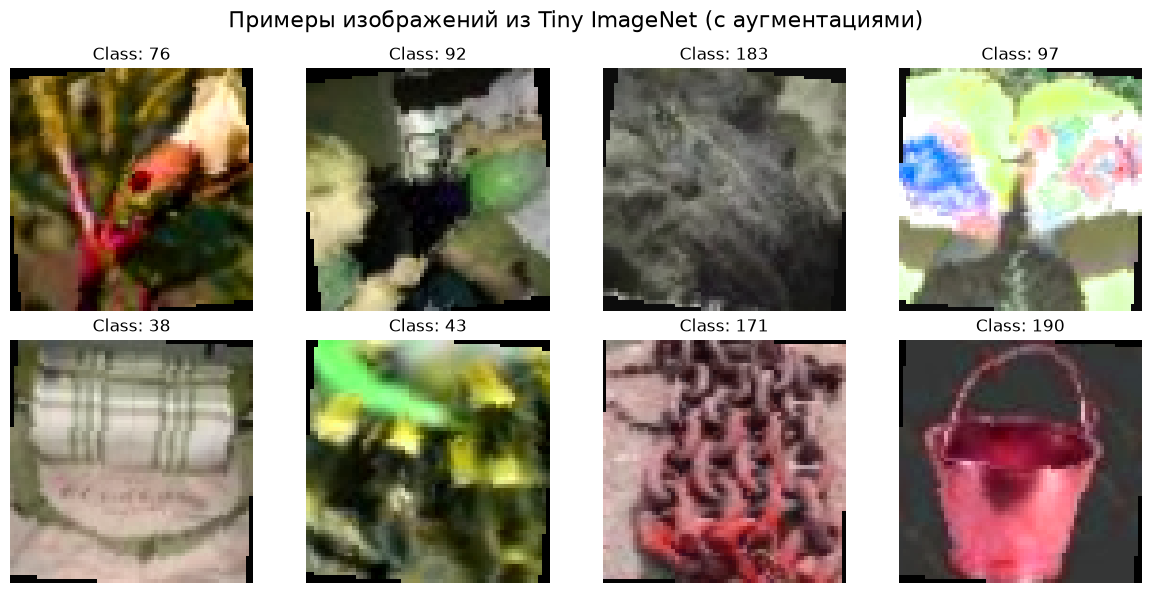

Размер батча: torch.Size([8, 3, 64, 64])
Диапазон значений: [-2.118, 2.640]
Метки классов: [76, 92, 183, 97, 38, 43, 171, 190]
Всего классов в датасете: 200
Примеры названий классов: ['n02124075', 'n04067472', 'n04540053', 'n04099969', 'n07749582']


In [7]:
images, labels = next(iter(train_loader))

def denormalize(img_tensor):
    """Вернём изображение из нормализованного диапазона в [0,1]"""
    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 1, 3)
    std = torch.tensor([0.229, 0.224, 0.225]).view(1, 1, 3)
    img = img_tensor.permute(1, 2, 0) * std + mean
    return img.clamp(0, 1)

images_vis = images.permute(0, 2, 3, 1)

images_vis = torch.stack([denormalize(img) for img in images])

plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i+1)
    plt.imshow(images_vis[i])
    plt.title(f"Class: {labels[i].item()}")
    plt.axis('off')
plt.suptitle("Примеры изображений из Tiny ImageNet (с аугментациями)", fontsize=16)
plt.tight_layout()
plt.show()

print(f"Размер батча: {images.shape}")
print(f"Диапазон значений: [{images.min():.3f}, {images.max():.3f}]")
print(f"Метки классов: {labels.tolist()}")
print(f"Всего классов в датасете: {len(train_dataset.class_names)}")
print(f"Примеры названий классов: {train_dataset.class_names[:5]}")

---


### Стратификация данных

### Что такое стратификация?
**Стратификация** - это метод разделения данных, при котором сохраняется пропорциональное представление классов в каждой части.

###  Зачем нужна стратификация?
- Обеспечивает равномерное распределение классов между train/val/test
- Предотвращает переобучение на доминирующих классах
- Дает более надежную оценку качества модели

###  Типы стратификации:
1. **Случайная стратификация** - простое случайное разделение
2. **K-Fold стратификация** - разделение на k частей
3. **Стратификация по эмбедингам** - разделение на основе семантических признаков

**Рассмотрим различные подходы:**


#### Метод 1: Простая случайная стратификация


In [8]:
print(" Метод 1: Простая случайная стратификация")

train_dataset = TinyImageNetDataset(root, split='train', transform=train_transform)
all_samples = train_dataset.samples

print(f" Всего образцов: {len(all_samples)}")

random.seed(42)
all_samples_copy = all_samples.copy()
random.shuffle(all_samples_copy)

val_fraction = 0.2
split_idx = int(len(all_samples_copy) * (1 - val_fraction))
train_split_random = all_samples_copy[:split_idx]
val_split_random = all_samples_copy[split_idx:]

print(" Случайное разделение:")
print(f"   Train: {len(train_split_random)} образцов")
print(f"   Val: {len(val_split_random)} образцов")

def analyze_class_distribution(samples, name):
    labels = [label for _, label in samples]
    class_counts = Counter(labels)
    print(f" {name} - распределение классов:")
    print(f"   Минимум: {min(class_counts.values())}")
    print(f"   Максимум: {max(class_counts.values())}")
    print(f"   Среднее: {np.mean(list(class_counts.values())):.1f}")
    print(f"   Стандартное отклонение: {np.std(list(class_counts.values())):.1f}")

analyze_class_distribution(train_split_random, "Случайное train")
analyze_class_distribution(val_split_random, "Случайное val")

 Метод 1: Простая случайная стратификация
 Всего образцов: 100000
 Случайное разделение:
   Train: 80000 образцов
   Val: 20000 образцов
 Случайное train - распределение классов:
   Минимум: 377
   Максимум: 424
   Среднее: 400.0
   Стандартное отклонение: 9.3
 Случайное val - распределение классов:
   Минимум: 76
   Максимум: 123
   Среднее: 100.0
   Стандартное отклонение: 9.3


#### Метод 2: Cтратификация с помощью sklearn


In [9]:


X = [x for x, y in all_samples]  # пути к изображениям
y = [y for x, y in all_samples]  # метки классов

print(f" Подготовлено {len(X)} образцов с {len(set(y))} классами")

sss = StratifiedShuffleSplit(n_splits=1, test_size=val_fraction, random_state=42)
train_idx, val_idx = next(sss.split(X, y))

# Создаем стратифицированные разделения
train_split_stratified = [all_samples[i] for i in train_idx]
val_split_stratified = [all_samples[i] for i in val_idx]

print(" Стратифицированное разделение:")
print(f"   Train: {len(train_split_stratified)} образцов")
print(f"   Val: {len(val_split_stratified)} образцов")

# Анализируем распределение классов
analyze_class_distribution(train_split_stratified, "Стратифицированное train")
analyze_class_distribution(val_split_stratified, "Стратифицированное val")

 Подготовлено 100000 образцов с 200 классами
 Стратифицированное разделение:
   Train: 80000 образцов
   Val: 20000 образцов
 Стратифицированное train - распределение классов:
   Минимум: 400
   Максимум: 400
   Среднее: 400.0
   Стандартное отклонение: 0.0
 Стратифицированное val - распределение классов:
   Минимум: 100
   Максимум: 100
   Среднее: 100.0
   Стандартное отклонение: 0.0


#### Метод 3: K-Fold стратификация


In [10]:
# K-Fold стратификация

k = 5
skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

print(f" Разделение на {k} фолдов:")
fold_splits = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    train_split = [all_samples[i] for i in train_idx]
    val_split = [all_samples[i] for i in val_idx]
    fold_splits.append((train_split, val_split))
    print(f"   Fold {fold}: train={len(train_split)}, val={len(val_split)}")

print(" Анализ первого фолда:")
analyze_class_distribution(fold_splits[0][0], "Fold 0 train")
analyze_class_distribution(fold_splits[0][1], "Fold 0 val")

 Разделение на 5 фолдов:
   Fold 0: train=80000, val=20000
   Fold 1: train=80000, val=20000
   Fold 2: train=80000, val=20000
   Fold 3: train=80000, val=20000
   Fold 4: train=80000, val=20000
 Анализ первого фолда:
 Fold 0 train - распределение классов:
   Минимум: 400
   Максимум: 400
   Среднее: 400.0
   Стандартное отклонение: 0.0
 Fold 0 val - распределение классов:
   Минимум: 100
   Максимум: 100
   Среднее: 100.0
   Стандартное отклонение: 0.0


## Стратификация через эмбединги

## Что такое стратификация через эмбединги?
Вместо разделения по классам, мы можем разделить данные по **семантическим признакам** (эмбедингам), извлеченным из изображений.

### Преимущества:
- Учитывает визуальное сходство изображений
- Может найти скрытые паттерны в данных
- Полезно когда классы неоднородны внутри себя

### Алгоритм:
1. Извлекаем эмбединги с помощью предобученной модели
2. Кластеризуем эмбединги (K-means)
3. Стратифицируем по кластерам


### Шаг 1: Создание подвыборки для демонстрации

Для демонстрации возьмем только несколько классов, чтобы ускорить процесс:


In [11]:
selected_classes = [0, 5, 10, 15, 20]  # 5 классов
subset_samples = [s for s in train_dataset.samples if s[1] in selected_classes]

print(f"Используем {len(subset_samples)} изображений из {len(selected_classes)} классов")
print(f"Выбранные классы: {selected_classes}")

class CustomDataset(Dataset):
    def __init__(self, samples, transform=None):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        img = Image.open(img_path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, label

train_subset_dataset = CustomDataset(subset_samples, transform=train_transform)
subset_loader = DataLoader(train_subset_dataset, batch_size=64, shuffle=False)

print(f"Создан датасет с {len(train_subset_dataset)} образцами")

Используем 2500 изображений из 5 классов
Выбранные классы: [0, 5, 10, 15, 20]
Создан датасет с 2500 образцами


### Шаг 2: Извлечение эмбедингов


In [12]:
print("🧠 Извлекаем эмбединги...")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"🖥️ Используем устройство: {device}")

resnet = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)
resnet = resnet.to(device)
resnet.eval()

# Создаем feature extractor (убираем последний слой)
feature_extractor = nn.Sequential(*list(resnet.children())[:-1])
feature_extractor = feature_extractor.to(device)

def extract_embeddings(images):
    """
    Извлекаем эмбединги из изображений
    images: батч [B, 3, H, W]
    """
    with torch.no_grad():
        x = feature_extractor(images)  # [B, 2048, 1, 1]
        x = x.view(x.size(0), -1)      # [B, 2048]
    return x

# Извлекаем эмбединги для всех изображений
all_embeddings = []
all_labels = []

print("Извлекаем эмбединги для всех изображений...")
for images, labels in tqdm(subset_loader, desc="Извлечение эмбедингов"):
    images = images.to(device)
    emb = extract_embeddings(images)  # [B, 2048]
    all_embeddings.append(emb.cpu())
    all_labels.append(labels)

all_embeddings = torch.cat(all_embeddings, dim=0).numpy()
all_labels = torch.cat(all_labels, dim=0).numpy()

print(f"Извлечено эмбедингов: {all_embeddings.shape}")
print(f"Размерность эмбединга: {all_embeddings.shape[1]}")
print(f"Количество меток: {len(all_labels)}")

🧠 Извлекаем эмбединги...
🖥️ Используем устройство: cuda
Извлекаем эмбединги для всех изображений...


Извлечение эмбедингов: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 40/40 [00:02<00:00, 13.66it/s]

Извлечено эмбедингов: (2500, 2048)
Размерность эмбединга: 2048
Количество меток: 2500


### Шаг 3: K-means кластеризация


In [13]:
n_clusters = 10
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)

pseudo_labels = kmeans.fit_predict(all_embeddings)

print(f"Создано {n_clusters} кластеров")
print(f"Распределение по кластерам: {Counter(pseudo_labels)}")

# Анализируем соответствие кластеров и исходных классов
cluster_class_mapping = {}
for cluster_id in range(n_clusters):
    cluster_indices = np.where(pseudo_labels == cluster_id)[0]
    cluster_classes = all_labels[cluster_indices]
    most_common_class = Counter(cluster_classes).most_common(1)[0]
    cluster_class_mapping[cluster_id] = most_common_class
    print(f"📊 Кластер {cluster_id}: {len(cluster_indices)} образцов, "
          f"доминирующий класс {most_common_class[0]} ({most_common_class[1]} образцов)")

Создано 10 кластеров
Распределение по кластерам: Counter({np.int32(8): 635, np.int32(4): 437, np.int32(6): 324, np.int32(1): 271, np.int32(7): 194, np.int32(9): 151, np.int32(3): 146, np.int32(0): 129, np.int32(2): 113, np.int32(5): 100})
📊 Кластер 0: 129 образцов, доминирующий класс 10 (129 образцов)
📊 Кластер 1: 271 образцов, доминирующий класс 0 (233 образцов)
📊 Кластер 2: 113 образцов, доминирующий класс 20 (113 образцов)
📊 Кластер 3: 146 образцов, доминирующий класс 0 (145 образцов)
📊 Кластер 4: 437 образцов, доминирующий класс 5 (326 образцов)
📊 Кластер 5: 100 образцов, доминирующий класс 20 (91 образцов)
📊 Кластер 6: 324 образцов, доминирующий класс 15 (310 образцов)
📊 Кластер 7: 194 образцов, доминирующий класс 20 (153 образцов)
📊 Кластер 8: 635 образцов, доминирующий класс 10 (313 образцов)
📊 Кластер 9: 151 образцов, доминирующий класс 5 (137 образцов)


### Шаг 4: Визуализация кластеров с помощью PCA


PCA объясняет 0.096 дисперсии
Компонента 1: 0.059
Компонента 2: 0.038


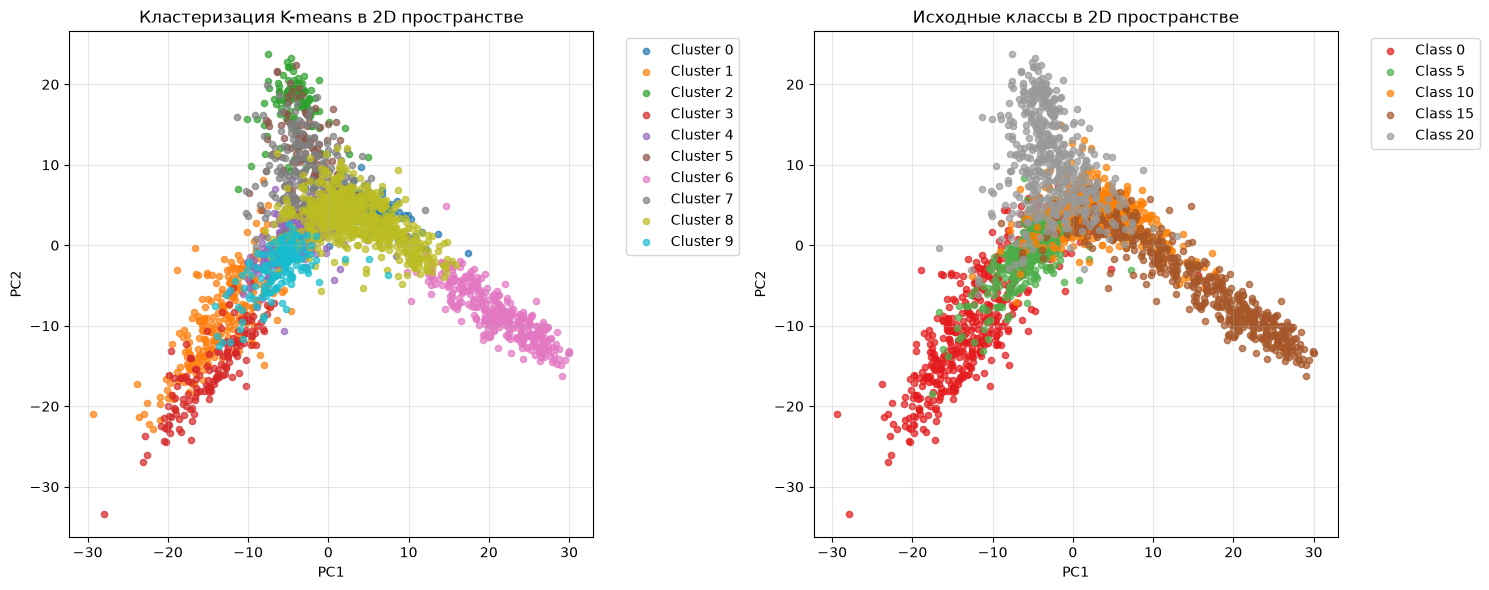

Анализ качества кластеризации:
Adjusted Rand Index: 0.360
Normalized Mutual Information: 0.514
Чем выше значения, тем лучше кластеризация соответствует исходным классам


In [14]:
# Применяем PCA для снижения размерности до 2D
pca = PCA(n_components=2, random_state=42)
emb_2d = pca.fit_transform(all_embeddings)

print(f"PCA объясняет {pca.explained_variance_ratio_.sum():.3f} дисперсии")
print(f"Компонента 1: {pca.explained_variance_ratio_[0]:.3f}")
print(f"Компонента 2: {pca.explained_variance_ratio_[1]:.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Визуализация по кластерам
colors = plt.cm.tab10(np.linspace(0, 1, n_clusters))
for cluster in range(n_clusters):
    indices = np.where(pseudo_labels == cluster)[0]
    ax1.scatter(emb_2d[indices, 0], emb_2d[indices, 1], 
               c=[colors[cluster]], label=f'Cluster {cluster}', s=20, alpha=0.7)

ax1.set_title("Кластеризация K-means в 2D пространстве")
ax1.set_xlabel("PC1")
ax1.set_ylabel("PC2")
ax1.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax1.grid(True, alpha=0.3)

# Визуализация по исходным классам
class_colors = plt.cm.Set1(np.linspace(0, 1, len(selected_classes)))
for i, class_id in enumerate(selected_classes):
    indices = np.where(all_labels == class_id)[0]
    ax2.scatter(emb_2d[indices, 0], emb_2d[indices, 1], 
               c=[class_colors[i]], label=f'Class {class_id}', s=20, alpha=0.7)

ax2.set_title("Исходные классы в 2D пространстве")
ax2.set_xlabel("PC1")
ax2.set_ylabel("PC2")
ax2.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Анализ качества кластеризации:")
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari_score = adjusted_rand_score(all_labels, pseudo_labels)
nmi_score = normalized_mutual_info_score(all_labels, pseudo_labels)

print(f"Adjusted Rand Index: {ari_score:.3f}")
print(f"Normalized Mutual Information: {nmi_score:.3f}")
print("Чем выше значения, тем лучше кластеризация соответствует исходным классам")

### Шаг 5: Стратификация по кластерам

Теперь разделим данные на train/val используя кластеры вместо исходных классов:


In [15]:
print("Стратифицируем данные по кластерам...")

sss_embedding = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx_embedding, val_idx_embedding = next(sss_embedding.split(subset_samples, pseudo_labels))

train_samples_embedding = [subset_samples[i] for i in train_idx_embedding]
val_samples_embedding = [subset_samples[i] for i in val_idx_embedding]

print(" Стратификация по эмбедингам:")
print(f"   Train: {len(train_samples_embedding)} образцов")
print(f"   Val: {len(val_samples_embedding)} образцов")

def analyze_embedding_split(samples, name):
    labels = [label for _, label in samples]
    class_counts = Counter(labels)
    print(f"📊 {name} - распределение исходных классов:")
    for class_id in selected_classes:
        count = class_counts.get(class_id, 0)
        percentage = count / len(labels) * 100
        print(f"   Класс {class_id}: {count} образцов ({percentage:.1f}%)")

analyze_embedding_split(train_samples_embedding, "Train (по эмбедингам)")
analyze_embedding_split(val_samples_embedding, "Val (по эмбедингам)")

Стратифицируем данные по кластерам...
 Стратификация по эмбедингам:
   Train: 2000 образцов
   Val: 500 образцов
📊 Train (по эмбедингам) - распределение исходных классов:
   Класс 0: 401 образцов (20.1%)
   Класс 5: 396 образцов (19.8%)
   Класс 10: 399 образцов (20.0%)
   Класс 15: 400 образцов (20.0%)
   Класс 20: 404 образцов (20.2%)
📊 Val (по эмбедингам) - распределение исходных классов:
   Класс 0: 99 образцов (19.8%)
   Класс 5: 104 образцов (20.8%)
   Класс 10: 101 образцов (20.2%)
   Класс 15: 100 образцов (20.0%)
   Класс 20: 96 образцов (19.2%)


---

## Часть 5: DataLoader с OpenCV и Albumentations

### Зачем использовать OpenCV?
- **Быстрее** чем PIL для некоторых операций
- **Больше возможностей** для аугментаций
- **Лучшая интеграция** с библиотекой Albumentations
- **Поддержка** различных форматов изображений

####  Что такое Albumentations?
- Современная библиотека для аугментаций
- Оптимизирована для компьютерного зрения
- Поддерживает как PIL, так и OpenCV
- Простой и гибкий API

** Создадим DataLoader с OpenCV и Albumentations:**


In [16]:
class TinyImageNetAlbumentationsDataset(Dataset):
    """
    Датасет Tiny ImageNet с OpenCV + Albumentations
    
    Преимущества:
    - Быстрая загрузка через OpenCV
    - Мощные аугментации через Albumentations
    - Поддержка различных форматов
    """
    def __init__(self, root_dir, split='train', augmentation=None):
        self.root_dir = root_dir
        self.split = split
        self.augmentation = augmentation

        # Загружаем названия классов
        with open(os.path.join(root_dir, 'wnids.txt'), 'r') as f:
            self.class_names = [line.strip() for line in f]
        self.class_to_idx = {name: i for i, name in enumerate(self.class_names)}
        
        print(f"📊 Найдено {len(self.class_names)} классов")

        # Собираем данные
        self.samples = self._make_dataset()
        print(f"📁 Загружено {len(self.samples)} образцов для {self.split}")

    def _make_dataset(self):
        """Создаем список образцов данных"""
        data = []

        if self.split == 'train':
            data = self._load_train_data()
        elif self.split == 'val':
            data = self._load_val_data()
        elif self.split == 'test':
            data = self._load_test_data()
        else:
            raise ValueError(f"Unknown split: {self.split}")

        return data

    def _load_train_data(self):
        """Загружаем тренировочные данные"""
        data = []
        train_dir = os.path.join(self.root_dir, 'train')
        for cls_name in os.listdir(train_dir):
            img_dir = os.path.join(train_dir, cls_name, 'images')
            if not os.path.isdir(img_dir):
                continue
            for img_name in os.listdir(img_dir):
                img_path = os.path.join(img_dir, img_name)
                label = self.class_to_idx[cls_name]
                data.append((img_path, label))
        return data

    def _load_val_data(self):
        """Загружаем валидационные данные"""
        data = []
        val_dir = os.path.join(self.root_dir, 'val')
        img_dir = os.path.join(val_dir, 'images')
        anno_file = os.path.join(val_dir, 'val_annotations.txt')

        label_map = {}
        with open(anno_file, 'r') as f:
            for line in f:
                img_name, cls_name, *_ = line.strip().split('\t')
                label_map[img_name] = self.class_to_idx[cls_name]

        for img_name in os.listdir(img_dir):
            if img_name in label_map:
                img_path = os.path.join(img_dir, img_name)
                label = label_map[img_name]
                data.append((img_path, label))
        return data

    def _load_test_data(self):
        """Загружаем тестовые данные"""
        data = []
        test_dir = os.path.join(self.root_dir, 'test', 'images')
        for img_name in os.listdir(test_dir):
            img_path = os.path.join(test_dir, img_name)
            data.append((img_path, -1))  # нет меток
        return data

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        """Возвращаем образец по индексу"""
        img_path, label = self.samples[idx]

        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # BGR -> RGB


        # Применяем аугментации
        if self.augmentation:
            augmented = self.augmentation(image=img)
            img = augmented['image']

        return img, label

### Создание аугментаций с помощью Albumentations


📊 Найдено 200 классов
📁 Загружено 100000 образцов для train
📊 Найдено 200 классов
📁 Загружено 10000 образцов для val
Train size: 100000
Val size: 10000
Тестируем OpenCV DataLoader...
Размер батча: torch.Size([8, 3, 64, 64])
Тип данных: torch.float32
Диапазон значений: [-2.118, 2.429]


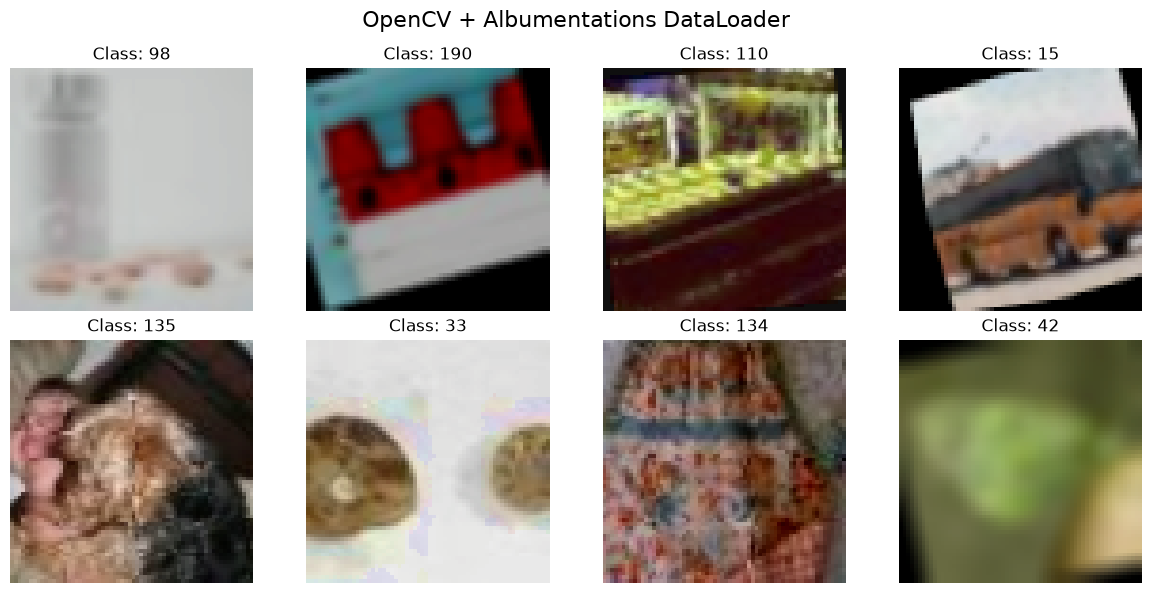

In [17]:
# Создаем мощные аугментации с помощью Albumentations

train_aug = A.Compose([
    # Изменение размера
    A.Resize(72, 72),
    A.RandomResizedCrop((64, 64), scale=(0.8, 1.0)),
    
    # Геометрические трансформации
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.1),
    A.Rotate(limit=15, p=0.5),
    A.Affine(
        translate_percent=(-0.1, 0.1),
        scale=(0.9, 1.1),
        rotate=(-15, 15),
        p=0.5
    ),
    
    # Цветовые аугментации
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.HueSaturationValue(hue_shift_limit=20, sat_shift_limit=30, val_shift_limit=20, p=0.3),
    A.RandomGamma(gamma_limit=(80, 120), p=0.3),
    
    # Шум и размытие
    A.GaussNoise(
        std_range=(np.sqrt(10.0) / 255.0, np.sqrt(50.0) / 255.0),
        p=0.2
    ),
    A.GaussianBlur(blur_limit=(3, 7), p=0.2),
    
    # Нормализация и преобразование в тензор
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

# Валидационные аугментации (только базовые)
val_aug = A.Compose([
    A.Resize(64, 64),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])



train_dataset_cv = TinyImageNetAlbumentationsDataset(
    root_dir="data/tiny-imagenet-200",
    split="train",
    augmentation=train_aug
)

val_dataset_cv = TinyImageNetAlbumentationsDataset(
    root_dir="data/tiny-imagenet-200",
    split="val",
    augmentation=val_aug
)

train_loader_cv = DataLoader(train_dataset_cv, batch_size=8, shuffle=True, num_workers=2)
val_loader_cv = DataLoader(val_dataset_cv, batch_size=8, shuffle=False, num_workers=2)

print(f"Train size: {len(train_dataset_cv)}")
print(f"Val size: {len(val_dataset_cv)}")

print("Тестируем OpenCV DataLoader...")
images_cv, labels_cv = next(iter(train_loader_cv))

print(f"Размер батча: {images_cv.shape}")
print(f"Тип данных: {images_cv.dtype}")
print(f"Диапазон значений: [{images_cv.min():.3f}, {images_cv.max():.3f}]")

# Визуализируем результаты
def denormalize_cv(img_tensor):
    """Денормализация для OpenCV изображений"""
    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 1, 3)
    std = torch.tensor([0.229, 0.224, 0.225]).view(1, 1, 3)
    img = img_tensor.permute(1, 2, 0) * std + mean
    return img.clamp(0, 1)

plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i+1)
    img_vis = denormalize_cv(images_cv[i])
    plt.imshow(img_vis)
    plt.title(f"Class: {labels_cv[i].item()}")
    plt.axis('off')
plt.suptitle("OpenCV + Albumentations DataLoader", fontsize=16)
plt.tight_layout()
plt.show()

---

### Создание кастомной ResNet модели


In [18]:
# Заполните пропуски в BasicBlock
class BasicBlock(nn.Module):
    """
    Базовый блок ResNet с residual connection
    
    Args:
        in_channels (int): количество входных каналов
        out_channels (int): количество выходных каналов
        stride (int): шаг свертки (по умолчанию 1)
        downsample (nn.Module): слой для изменения размерности (если нужно)
        activation (Callable[[], nn.Module]): фабрика построения функций активации слоя
    """
    
    expansion = 1
    
    def __init__(
        self,
        in_channels: int,
        out_channels: int,
        stride: int = 1,
        downsample: nn.Module | None = None,
        activation: Callable[[], nn.Module] = partial(
            nn.ReLU, inplace=True
        )
    ):
        super().__init__()
        self.expansion = 1 # Множитель числа выходных каналов выхода: out_channels = 4 * in_channels
        
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, stride=stride)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, stride=1)
        self.bn2 = nn.BatchNorm2d(out_channels)
        
        self.downsample = downsample

        self.activation = activation()

    def forward(self, x):
        identity = x
        
        x = self.activation(self.bn1(self.conv1(x)))
        x = self.bn2(self.conv2(x))
        
        if self.downsample is not None:
            identity = self.downsample(identity)

        x = self.activation(x + identity)
        return x





basic_block = BasicBlock(64, 128, stride=2, downsample=nn.Sequential(
                nn.Conv2d(64, 128, kernel_size=1, stride=2, padding=0),
                nn.BatchNorm2d(128)
            ))
test_input = torch.randn(2, 64, 32, 32)

output = basic_block(test_input)
print(test_input.shape)
print(output.shape)

torch.Size([2, 64, 32, 32])
torch.Size([2, 128, 16, 16])


In [19]:
class BottleneckBlock(nn.Module):
    """
    Bottleneck блок ResNet (1x1 -> 3x3 -> 1x1)
    Более эффективен для глубоких сетей
    
    Args:
        in_channels (int): количество входных каналов
        out_channels (int): количество выходных каналов
        stride (int): шаг свертки
        downsample (nn.Module): тип слоя для изменения размерности
        activation (Callable[[], nn.Module]: фабрика функции активации слоя
    """

    expansion = 4 # Множитель промежуточных каналов относительно выхода
    
    def __init__(
        self,
        in_channels: int,
        out_channels: int,
        stride: int = 1,
        downsample: nn.Module | None = None,
        activation: Callable[[], nn.Module] = partial(
            nn.ReLU, inplace=True
        )
    ):
        super().__init__()
        mid_channels = out_channels // self.expansion
        
        self.conv1 = nn.Conv2d(in_channels, mid_channels, kernel_size=1, stride=1, padding=0)
        self.bn1 = nn.BatchNorm2d(mid_channels)
        self.conv2 = nn.Conv2d(mid_channels, mid_channels, kernel_size=3, stride=stride, padding=1)
        self.bn2 = nn.BatchNorm2d(mid_channels)
        self.conv3 = nn.Conv2d(mid_channels, out_channels, kernel_size=1, stride=1, padding=0)
        self.bn3 = nn.BatchNorm2d(out_channels)
        
        self.downsample = downsample

        self.activation = activation()

    def forward(self, x):
        identity = x
        
        x = self.activation(self.bn1(self.conv1(x)))
        x = self.activation(self.bn2(self.conv2(x)))
        x = self.bn3(self.conv3(x))
        
        if self.downsample is not None:
            identity = self.downsample(identity)
            
        x = self.activation(x + identity)
        
        return x


bottleneck_block = BottleneckBlock(64, 256, stride=2, downsample=nn.Sequential(
    nn.Conv2d(64, 256, kernel_size=1, stride=2), nn.BatchNorm2d(256)
))
test_input = torch.randn(2, 64, 32, 32)

output = bottleneck_block(test_input)
print(test_input.shape)
print(output.shape)

torch.Size([2, 64, 32, 32])
torch.Size([2, 256, 16, 16])


### Архитектура ResNet



In [20]:
import torch
from torch import nn


class SimpleResNet18(nn.Module):
    """
    ResNet18
    
    Args:
        num_classes (int): число классов
        stages (list[tuple[int, int]]): список числа блоков слоя и соответствующих слою каналов
        block_type (type[nn.Module]): тип блока сети
        activation (Callable[[], nn.Module]: фабрика функций активации сети
    """

    def __init__(
        self,
        num_classes: int = 10,
        stages: Sequence[tuple[int, int]] = ((2, 64), (2, 128), (2,256), (2, 512)),
        block_type: type[nn.Module] = BasicBlock,
        activation: Callable[[], nn.Module] = partial(
            nn.ReLU, inplace=True
        )    
    ):
        super().__init__()

        current_channels = stages[0][1] # Количество каналов на входе первого слоя
        self.conv1 = nn.Conv2d(3, current_channels, kernel_size=3, stride=1, padding=1) # для TinyImageNet небольшая свертка без MaxPool
        self.bn1 = nn.BatchNorm2d(current_channels)
        
        self.activation = activation()

        backbone = []
        for idx, (num_blocks, num_channels) in enumerate(stages):
            if idx == 0:
                stride = 1
                downsample = None
            else:
                stride = 2
                downsample = self._make_downsample(
                    current_channels,
                    num_channels,
                    stride=stride
                )
            
            backbone.append(
                self._make_stage(
                    in_channels=current_channels,
                    out_channels=num_channels,
                    num_blocks=num_blocks,
                    stride=stride,
                    downsample=downsample,
                    block_type=block_type,
                    activation=activation
                )
            )
            current_channels = num_channels

        self.backbone = nn.Sequential(*backbone)

        self.avg_pool = nn.AdaptiveAvgPool2d(output_size=(1,1))
        self.head = nn.Sequential(
            nn.Linear(current_channels, num_classes)
        )

    def _make_downsample(self, in_channels, out_channels, stride):
        return nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, padding=0),
            nn.BatchNorm2d(out_channels)
        )

    def _make_stage(self,
        in_channels: int,
        out_channels: int,
        num_blocks: int,
        stride: int,
        downsample: nn.Module,
        block_type: type[nn.Module],
        activation: Callable[[], nn.Module] = partial(
            nn.ReLU, inplace=True
        )
    ) -> nn.Sequential:
        blocks = []

        blocks.append(
            block_type(
                in_channels,
                out_channels,
                stride=stride,
                downsample=downsample,
                activation=activation
            )
        )

        for block_idx in range(num_blocks - 1):
            blocks.append(block_type(out_channels, out_channels, activation=activation))

        return nn.Sequential(*blocks)

    def forward(self, x):
        x = self.activation(self.bn1(self.conv1(x)))

        x = self.backbone(x)
        x = self.avg_pool(x)
        x = x.view(x.size(0), -1)
        x = self.head(x)

        return x


model = SimpleResNet18(
    num_classes=10,
    stages=[
        (1, 32),
        (1, 64),
        (1, 128)
    ],
    activation = nn.ReLU
)
test_input = torch.randn(1, 3, 64, 64)

output = model(test_input)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f" Всего параметров: {total_params:,}")
print(f" Обучаемых параметров: {trainable_params:,}")

 Всего параметров: 309,322
 Обучаемых параметров: 309,322


In [21]:
# Обучение
def train_epoch(model, train_loader, optimizer, criterion, device):
    """
    Функция для одной эпохи обучения
    
    Args:
        model: модель для обучения
        train_loader: DataLoader с тренировочными данными
        optimizer: оптимизатор
        criterion: функция потерь
        device: устройство (cpu/cuda)
    
    Returns:
        train_loss: средняя потеря за эпох
        train_acc: средняя точность за эпох
    """
    model.train()  # Переводим модель в режим обучения
    
    running_loss = 0.0
    correct = 0
    total = 0
    

    pbar = tqdm(train_loader, desc="Training")
    
    for batch_idx, (data, target) in enumerate(pbar):
        batch_size = data.shape[0]
        
        data = data.to(device)
        target = target.to(device)
        
        optimizer.zero_grad()
        logits = model(data)
        
        loss = criterion(logits, target)
        correct += (logits.argmax(dim=1) == target).sum().item()
        running_loss += loss.item() * batch_size
        total += batch_size

        loss.backward()
        optimizer.step()

    train_loss = running_loss / total
    train_accuracy = correct / total

    
    return train_loss, train_accuracy

## 🔍 Задание 2: Функция валидации

In [22]:
def validate_epoch(model, val_loader, criterion, device):
    """
    Функция для валидации модели
    
    Args:
        model: модель для валидации
        val_loader: DataLoader с валидационными данными
        criterion: функция потерь
        device: устройство (cpu/cuda)
    
    Returns:
        val_loss: средняя потеря на валидации
        val_acc: средняя точность на валидации
    """
    model.eval()  # Переводим модель в режим оценки
    
    running_loss = 0.0
    correct = 0
    total = 0
    
    pbar = tqdm(val_loader, desc="Validation")
    
    with torch.no_grad():  # Отключаем вычисление градиентов
        for batch_idx, (data, target) in enumerate(pbar):
            batch_size = data.shape[0]
            
            data = data.to(device)
            target = target.to(device)
            
            logits = model(data)
            
            loss = criterion(logits, target)
            correct += (logits.argmax(dim=1) == target).sum().item()
            running_loss += loss.item() * batch_size
            total += batch_size

        val_loss = running_loss / total
        val_accuracy = correct / total
    
    return val_loss, val_accuracy

In [23]:
def train_model(model, train_loader, val_loader, optimizer, criterion, device, num_epochs=10):
    """
    Основная функция для обучения модели
    
    Args:
        model: модель для обучения
        train_loader: DataLoader с тренировочными данными
        val_loader: DataLoader с валидационными данными
        optimizer: оптимизатор
        criterion: функция потерь
        device: устройство (cpu/cuda)
        num_epochs: количество эпох
    
    Returns:
        history: словарь с историей обучения
    """
    print(f"Обучение на {num_epochs} эпох...")
    
    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': []
    }
    
    model = model.to(device)
    
    best_val_acc = 0.0
    
    for epoch in range(num_epochs):
        print(f" Эпоха {epoch+1}/{num_epochs}")
        
        train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion, device)
        
        val_loss, val_acc = validate_epoch(model, val_loader, criterion, device)
        
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        
        print(f" Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%")
        print(f" Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")
        
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), 'best_model.pth')
            print(f" Сохранена лучшая модель с точностью {val_acc:.2f}%")
        
    
    return history

In [24]:
def plot_training_history(history):

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    

    ax1.plot(history['train_loss'], label='Train Loss', color='blue')
    ax1.plot(history['val_loss'], label='Validation Loss', color='red')
    ax1.set_title('Training and Validation Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True)
    
    ax2.plot(history['train_acc'], label='Train Accuracy', color='blue')
    ax2.plot(history['val_acc'], label='Validation Accuracy', color='red')
    ax2.set_title('Training and Validation Accuracy')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy (%)')
    ax2.legend()
    ax2.grid(True)
    
    plt.tight_layout()
    plt.show()

### Обучение



In [25]:
# Для быстрого теста можно использовать только несколько классов

selected_classes = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

subset_train_samples = [s for s in train_dataset.samples if s[1] in selected_classes]
subset_val_samples = [s for s in val_dataset.samples if s[1] in selected_classes]

print(f"Используем {len(subset_train_samples)} train и {len(subset_val_samples)} val изображений "
      f"из {len(selected_classes)} классов")

# Перенумеровка классов
class_to_new_idx = {cls: i for i, cls in enumerate(selected_classes)}

def remap_samples(samples):
    return [(path, class_to_new_idx[label]) for path, label in samples]

subset_train_samples = remap_samples(subset_train_samples)
subset_val_samples = remap_samples(subset_val_samples)


class CustomDataset(Dataset):
    def __init__(self, samples, transform=None):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        img = Image.open(img_path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, label

Используем 5000 train и 500 val изображений из 10 классов


### Эксперименты

In [26]:
experiments_data = []

#### SEED
Для всех экспериментов одинаковый, сбрасывается перед каждым экспериментом

In [27]:
SEED = 42

#### Baseline

 Всего параметров: 2,779,914
 Обучаемых параметров: 2,779,914
SimpleResNet18(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (activation): ReLU(inplace=True)
  (backbone): Sequential(
    (0): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (activation): ReLU(inplace=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  

Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 29.96it/s]


 Train Loss: 2.0454, Train Acc: 0.28%
 Val Loss: 2.3442, Val Acc: 0.20%
 Сохранена лучшая модель с точностью 0.20%
 Эпоха 2/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 30.23it/s]


 Train Loss: 1.8674, Train Acc: 0.35%
 Val Loss: 2.0271, Val Acc: 0.31%
 Сохранена лучшая модель с точностью 0.31%
 Эпоха 3/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 30.23it/s]


... (51 outputs left out)

Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 30.34it/s]


 Train Loss: 0.8323, Train Acc: 0.72%
 Val Loss: 1.6660, Val Acc: 0.47%
 Эпоха 30/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 30.31it/s]


 Train Loss: 0.8142, Train Acc: 0.72%
 Val Loss: 1.2197, Val Acc: 0.62%
 Сохранена лучшая модель с точностью 0.62%


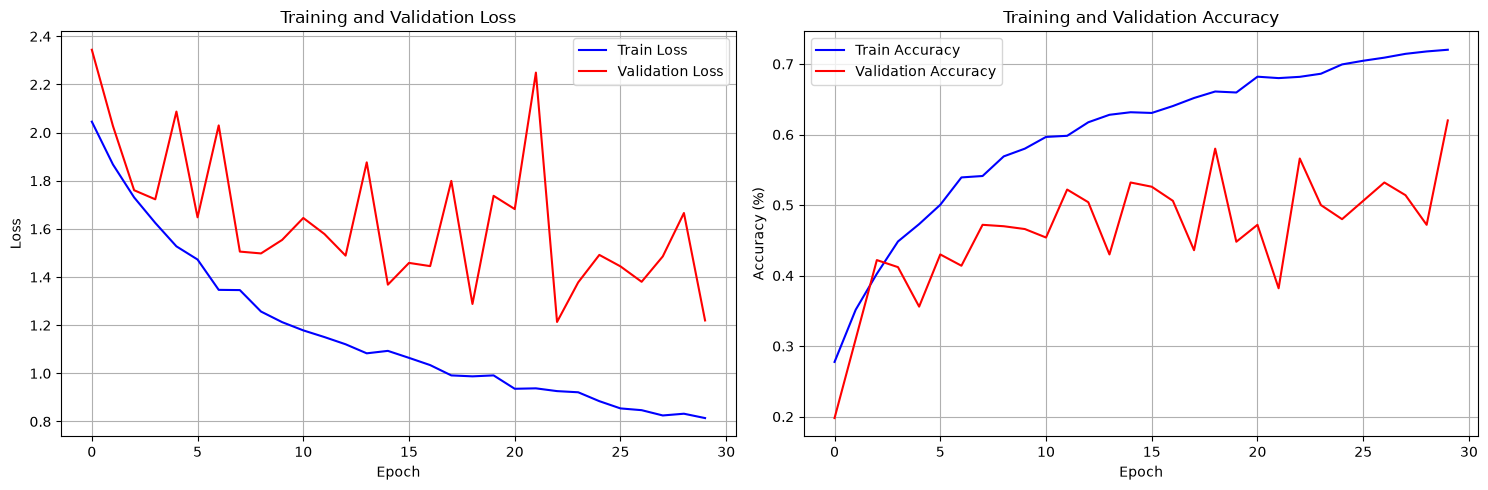

In [28]:
seed_everything(SEED)


model = SimpleResNet18(
    num_classes=10,
    stages=[
        (2, 64),
        (2, 128),
        (2, 256)
    ]
)

train_subset_dataset = CustomDataset(subset_train_samples, transform=train_transform)
val_subset_dataset = CustomDataset(subset_val_samples, transform=val_transform)

train_loader = DataLoader(train_subset_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_subset_dataset, batch_size=64, shuffle=False)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f" Всего параметров: {total_params:,}")
print(f" Обучаемых параметров: {trainable_params:,}")
print(model)

history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    criterion=criterion,
    device=device,
    num_epochs=30
)

plot_training_history(history)

best_epoch = int(np.argmax(history["val_acc"]))
experiments_data.append(
    {
        "configuration": "baseline",
        "total_params": total_params,
        "trainable_params": trainable_params,
        "final_val_acc": history["val_acc"][-1],
        "final_train_acc": history["train_acc"][-1],
        "best_val_acc": history["val_acc"][best_epoch],
        "best_train_acc": history["val_acc"][best_epoch],
        "best_epoch": best_epoch
    }
)

In [29]:
pd.DataFrame(experiments_data)

,configuration,total_params,trainable_params,final_val_acc,final_train_acc,best_val_acc,best_train_acc,best_epoch
0,baseline,2779914,2779914,0.62,0.7202,0.62,0.62,29


#### Оптимизация количества каналов
#### A: 32 -> 64 -> 128 -> 256

 Всего параметров: 1,230,410
 Обучаемых параметров: 1,230,410
SimpleResNet18(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (activation): ReLU(inplace=True)
  (backbone): Sequential(
    (0): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (activation): ReLU(inplace=True)
      )
    )
    (1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, t

Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 48.29it/s]


 Train Loss: 2.0202, Train Acc: 0.28%
 Val Loss: 2.0592, Val Acc: 0.32%
 Сохранена лучшая модель с точностью 0.32%
 Эпоха 2/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 48.70it/s]


 Train Loss: 1.8061, Train Acc: 0.37%
 Val Loss: 1.7914, Val Acc: 0.39%
 Сохранена лучшая модель с точностью 0.39%
 Эпоха 3/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 48.88it/s]


... (51 outputs left out)

Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 49.09it/s]


 Train Loss: 0.7486, Train Acc: 0.74%
 Val Loss: 1.6122, Val Acc: 0.52%
 Эпоха 30/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 49.02it/s]


 Train Loss: 0.7201, Train Acc: 0.75%
 Val Loss: 1.7467, Val Acc: 0.47%


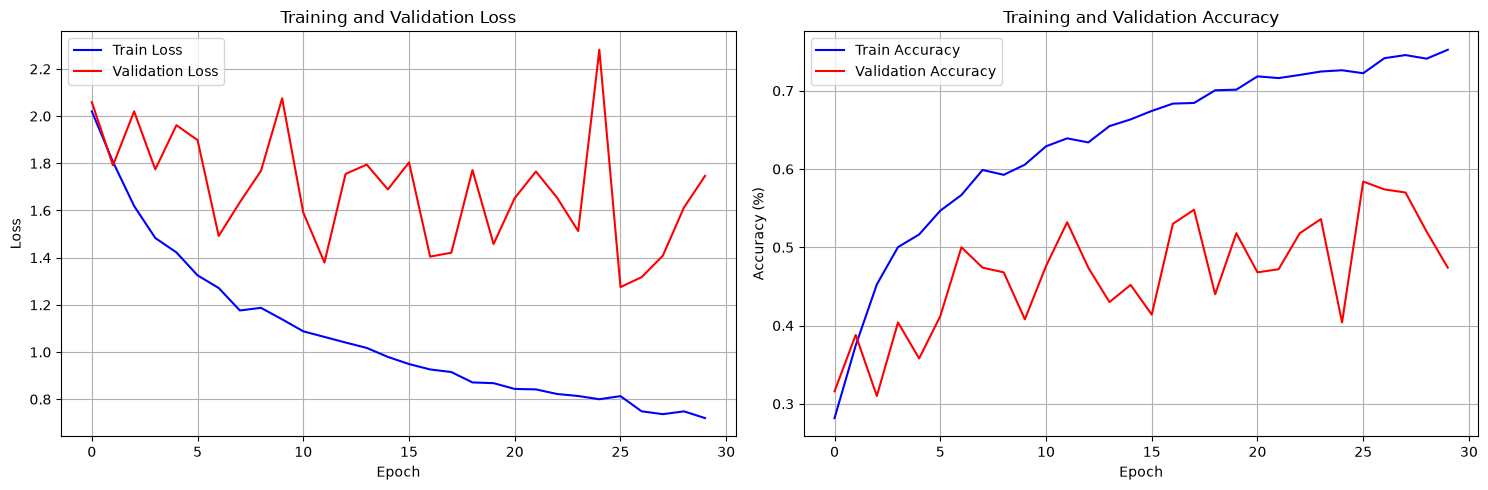

In [30]:
seed_everything(SEED)


model = SimpleResNet18(
    num_classes=10,
    stages=[
        (1, 32),
        (1, 64),
        (1, 128),
        (1, 256)
    ]
)

train_subset_dataset = CustomDataset(subset_train_samples, transform=train_transform)
val_subset_dataset = CustomDataset(subset_val_samples, transform=val_transform)

train_loader = DataLoader(train_subset_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_subset_dataset, batch_size=64, shuffle=False)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f" Всего параметров: {total_params:,}")
print(f" Обучаемых параметров: {trainable_params:,}")
print(model)

history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    criterion=criterion,
    device=device,
    num_epochs=30
)

plot_training_history(history)

best_epoch = int(np.argmax(history["val_acc"]))
experiments_data.append(
    {
        "configuration": "32->64->128->256",
        "total_params": total_params,
        "trainable_params": trainable_params,
        "final_val_acc": history["val_acc"][-1],
        "final_train_acc": history["train_acc"][-1],
        "best_val_acc": history["val_acc"][best_epoch],
        "best_train_acc": history["val_acc"][best_epoch],
        "best_epoch": best_epoch
    }
)

#### B: 64 -> 128 -> 256

 Всего параметров: 1,228,938
 Обучаемых параметров: 1,228,938
SimpleResNet18(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (activation): ReLU(inplace=True)
  (backbone): Sequential(
    (0): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (activation): ReLU(inplace=True)
      )
    )
    (1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
        (bn1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True,

Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 37.85it/s]


 Train Loss: 1.9854, Train Acc: 0.30%
 Val Loss: 2.0857, Val Acc: 0.28%
 Сохранена лучшая модель с точностью 0.28%
 Эпоха 2/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 38.09it/s]


 Train Loss: 1.8058, Train Acc: 0.38%
 Val Loss: 2.0866, Val Acc: 0.30%
 Сохранена лучшая модель с точностью 0.30%
 Эпоха 3/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 37.79it/s]


... (51 outputs left out)

Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 37.98it/s]


 Train Loss: 0.8598, Train Acc: 0.71%
 Val Loss: 1.4237, Val Acc: 0.54%
 Эпоха 30/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 38.02it/s]


 Train Loss: 0.8426, Train Acc: 0.72%
 Val Loss: 1.3566, Val Acc: 0.54%


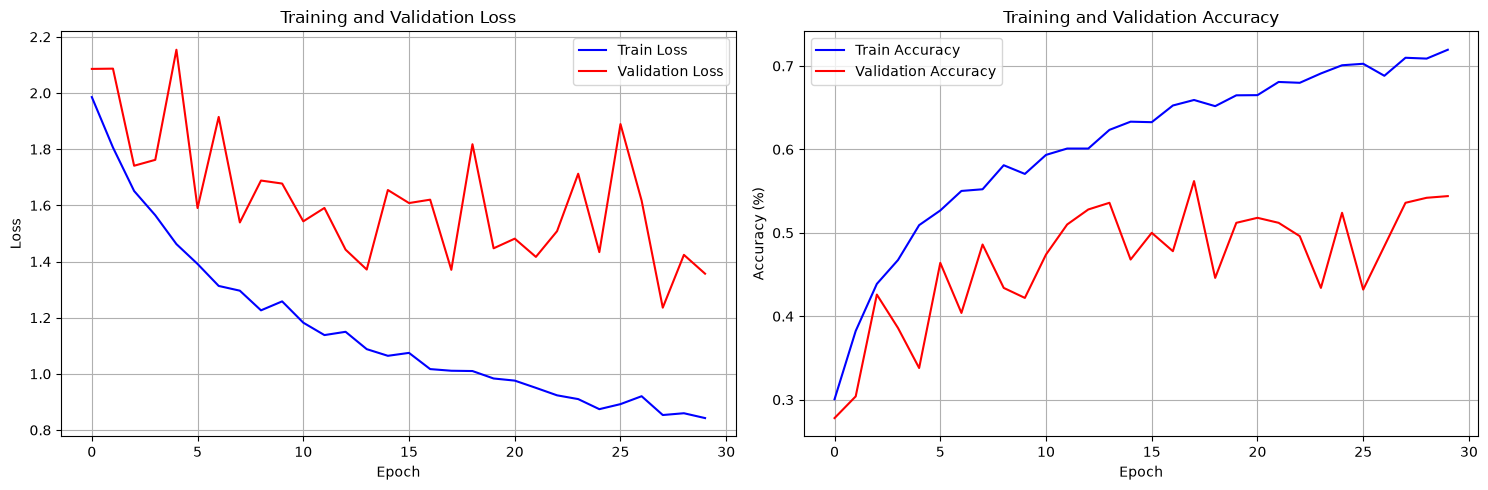

In [31]:
seed_everything(SEED)


model = SimpleResNet18(
    num_classes=10,
    stages=[
        (1, 64),
        (1, 128),
        (1, 256)
    ]
)

train_subset_dataset = CustomDataset(subset_train_samples, transform=train_transform)
val_subset_dataset = CustomDataset(subset_val_samples, transform=val_transform)

train_loader = DataLoader(train_subset_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_subset_dataset, batch_size=64, shuffle=False)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f" Всего параметров: {total_params:,}")
print(f" Обучаемых параметров: {trainable_params:,}")
print(model)

history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    criterion=criterion,
    device=device,
    num_epochs=30
)

plot_training_history(history)

best_epoch = int(np.argmax(history["val_acc"]))
experiments_data.append(
    {
        "configuration": "64->128->256",
        "total_params": total_params,
        "trainable_params": trainable_params,
        "final_val_acc": history["val_acc"][-1],
        "final_train_acc": history["train_acc"][-1],
        "best_val_acc": history["val_acc"][best_epoch],
        "best_train_acc": history["val_acc"][best_epoch],
        "best_epoch": best_epoch
    }
)

#### Лучшая конфигурация (по best_val_acc): 32->64->128->256
Для достижения лучшей метрики понадобилось 25 эпох, в альтернативном варианте - 17 эпох, число параметров отличается примерно на 1000

In [32]:
pd.DataFrame(experiments_data)

,configuration,total_params,trainable_params,final_val_acc,final_train_acc,best_val_acc,best_train_acc,best_epoch
0,baseline,2779914,2779914,0.620,0.7202,0.620,0.620,29
1,32->64->128->256,1230410,1230410,0.474,0.7524,0.584,0.584,25
2,64->128->256,1228938,1228938,0.544,0.7194,0.562,0.562,17


#### Оптимизация количества блоков
#### A: [1, 1, 1, 1]

 Всего параметров: 1,230,410
 Обучаемых параметров: 1,230,410
SimpleResNet18(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (activation): ReLU(inplace=True)
  (backbone): Sequential(
    (0): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (activation): ReLU(inplace=True)
      )
    )
    (1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, t

Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 48.40it/s]


 Train Loss: 2.0185, Train Acc: 0.28%
 Val Loss: 2.1449, Val Acc: 0.31%
 Сохранена лучшая модель с точностью 0.31%
 Эпоха 2/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 49.25it/s]


 Train Loss: 1.8039, Train Acc: 0.37%
 Val Loss: 1.8216, Val Acc: 0.38%
 Сохранена лучшая модель с точностью 0.38%
 Эпоха 3/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 49.28it/s]


... (51 outputs left out)

Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 49.39it/s]


 Train Loss: 0.7356, Train Acc: 0.75%
 Val Loss: 1.6080, Val Acc: 0.52%
 Эпоха 30/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 49.28it/s]


 Train Loss: 0.7105, Train Acc: 0.76%
 Val Loss: 1.7887, Val Acc: 0.48%


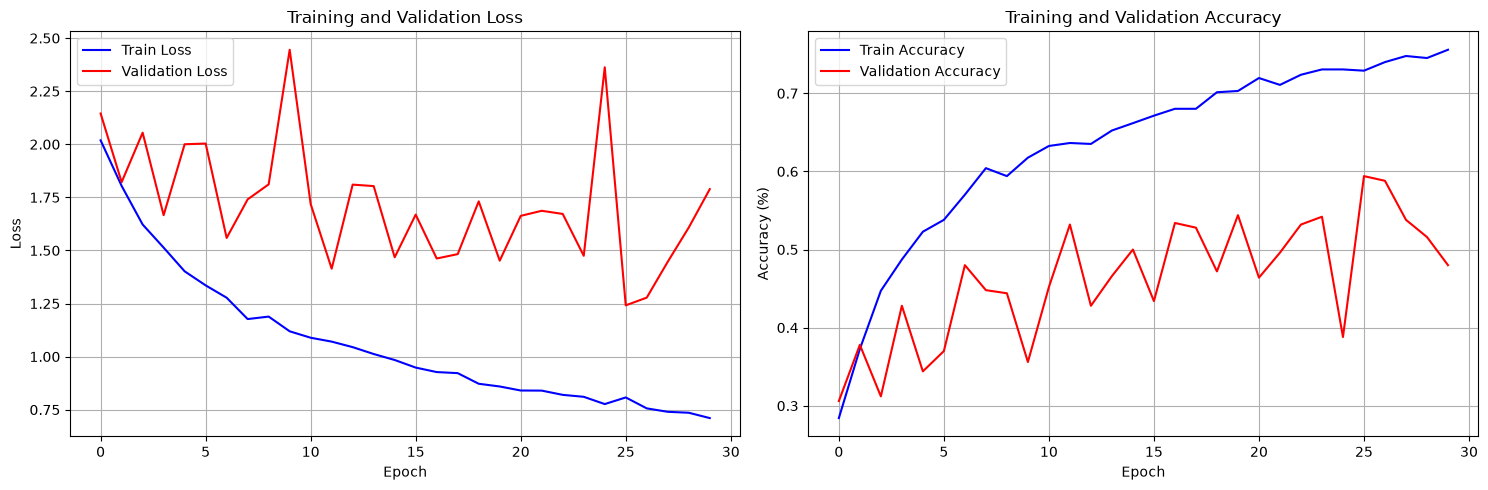

In [33]:
seed_everything(SEED)


model = SimpleResNet18(
    num_classes=10,
    stages=[
        (1, 32),
        (1, 64),
        (1, 128),
        (1, 256)
    ]
)

train_subset_dataset = CustomDataset(subset_train_samples, transform=train_transform)
val_subset_dataset = CustomDataset(subset_val_samples, transform=val_transform)

train_loader = DataLoader(train_subset_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_subset_dataset, batch_size=64, shuffle=False)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f" Всего параметров: {total_params:,}")
print(f" Обучаемых параметров: {trainable_params:,}")
print(model)

history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    criterion=criterion,
    device=device,
    num_epochs=30
)

plot_training_history(history)

best_epoch = int(np.argmax(history["val_acc"]))
experiments_data.append(
    {
        "configuration": "[1,1,1,1]",
        "total_params": total_params,
        "trainable_params": trainable_params,
        "final_val_acc": history["val_acc"][-1],
        "final_train_acc": history["train_acc"][-1],
        "best_val_acc": history["val_acc"][best_epoch],
        "best_train_acc": history["val_acc"][best_epoch],
        "best_epoch": best_epoch
    }
)

#### B: [2, 2, 2, 2]

 Всего параметров: 2,800,010
 Обучаемых параметров: 2,800,010
SimpleResNet18(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (activation): ReLU(inplace=True)
  (backbone): Sequential(
    (0): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (activation): ReLU(inplace=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  

Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 44.48it/s]


 Train Loss: 2.0517, Train Acc: 0.28%
 Val Loss: 2.2300, Val Acc: 0.27%
 Сохранена лучшая модель с точностью 0.27%
 Эпоха 2/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 43.61it/s]


 Train Loss: 1.8254, Train Acc: 0.37%
 Val Loss: 2.1764, Val Acc: 0.30%
 Сохранена лучшая модель с точностью 0.30%
 Эпоха 3/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 44.61it/s]


... (51 outputs left out)

Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 44.49it/s]


 Train Loss: 0.7089, Train Acc: 0.76%
 Val Loss: 1.4068, Val Acc: 0.56%
 Эпоха 30/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 44.52it/s]


 Train Loss: 0.6906, Train Acc: 0.76%
 Val Loss: 1.3316, Val Acc: 0.56%


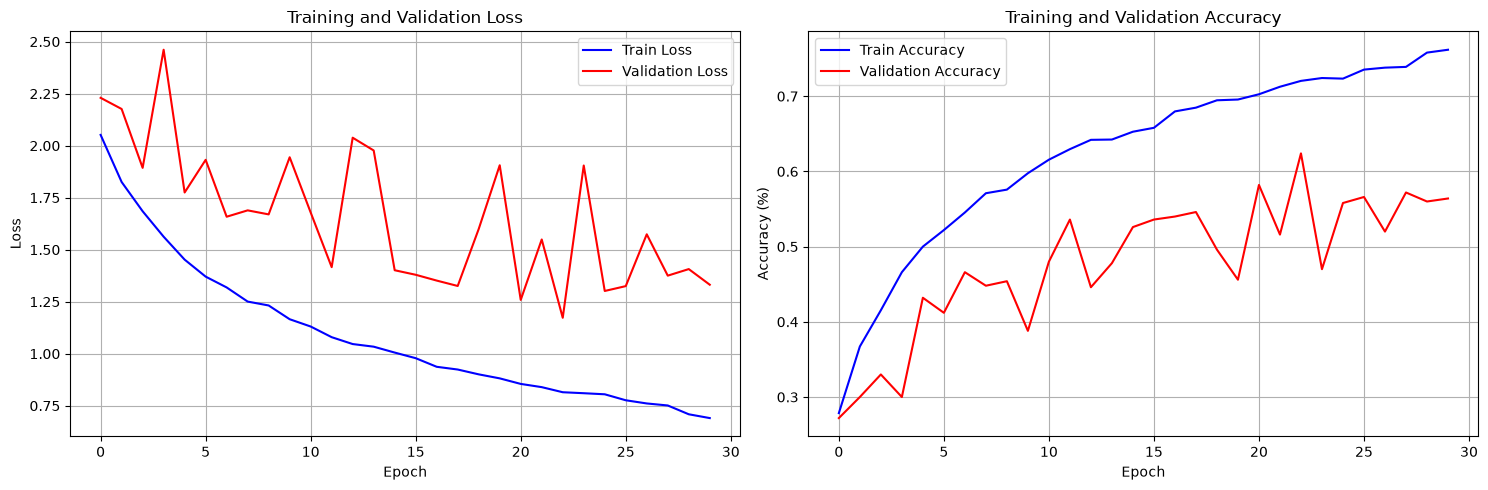

In [34]:
seed_everything(SEED)


model = SimpleResNet18(
    num_classes=10,
    stages=[
        (2, 32),
        (2, 64),
        (2, 128),
        (2, 256)
    ]
)

train_subset_dataset = CustomDataset(subset_train_samples, transform=train_transform)
val_subset_dataset = CustomDataset(subset_val_samples, transform=val_transform)

train_loader = DataLoader(train_subset_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_subset_dataset, batch_size=64, shuffle=False)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f" Всего параметров: {total_params:,}")
print(f" Обучаемых параметров: {trainable_params:,}")
print(model)

history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    criterion=criterion,
    device=device,
    num_epochs=30
)

plot_training_history(history)

best_epoch = int(np.argmax(history["val_acc"]))
experiments_data.append(
    {
        "configuration": "[2,2,2,2]",
        "total_params": total_params,
        "trainable_params": trainable_params,
        "final_val_acc": history["val_acc"][-1],
        "final_train_acc": history["train_acc"][-1],
        "best_val_acc": history["val_acc"][best_epoch],
        "best_train_acc": history["val_acc"][best_epoch],
        "best_epoch": best_epoch
    }
)

#### C: [3, 3, 3, 3] c BottleneckBlock

 Всего параметров: 321,050
 Обучаемых параметров: 321,050
SimpleResNet18(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (activation): ReLU(inplace=True)
  (backbone): Sequential(
    (0): Sequential(
      (0): BottleneckBlock(
        (conv1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
        (bn1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(8, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (bn2): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv3): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
        (bn3): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (activation): ReLU(inplace=True)
      )
      (1): BottleneckBlock(
        (conv1): Conv2d(32, 8, ker

Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 44.28it/s]


 Train Loss: 2.0474, Train Acc: 0.26%
 Val Loss: 2.3682, Val Acc: 0.25%
 Сохранена лучшая модель с точностью 0.25%
 Эпоха 2/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 45.03it/s]


 Train Loss: 1.8730, Train Acc: 0.34%
 Val Loss: 2.3282, Val Acc: 0.28%
 Сохранена лучшая модель с точностью 0.28%
 Эпоха 3/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 44.95it/s]


... (51 outputs left out)

Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 45.08it/s]


 Train Loss: 0.9616, Train Acc: 0.67%
 Val Loss: 1.2767, Val Acc: 0.58%
 Эпоха 30/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 45.10it/s]


 Train Loss: 0.9199, Train Acc: 0.68%
 Val Loss: 1.5874, Val Acc: 0.51%


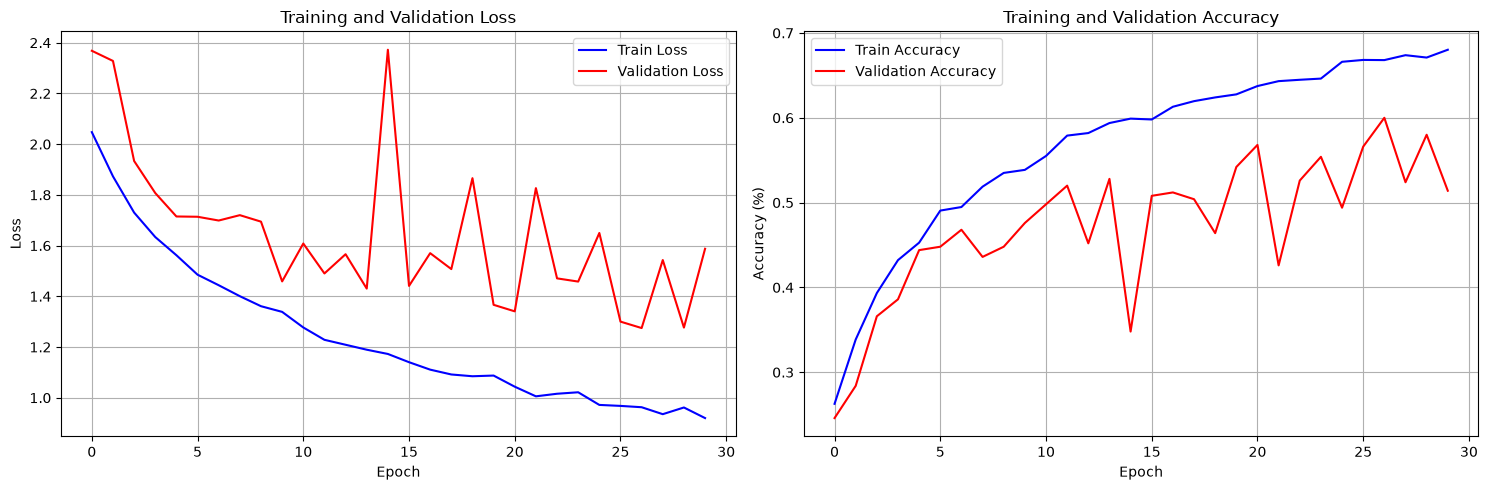

In [35]:
seed_everything(SEED)


model = SimpleResNet18(
    num_classes=10,
    stages=[
        (3, 32),
        (3, 64),
        (3, 128),
        (3, 256)
    ],
    block_type=BottleneckBlock
)

train_subset_dataset = CustomDataset(subset_train_samples, transform=train_transform)
val_subset_dataset = CustomDataset(subset_val_samples, transform=val_transform)

train_loader = DataLoader(train_subset_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_subset_dataset, batch_size=64, shuffle=False)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f" Всего параметров: {total_params:,}")
print(f" Обучаемых параметров: {trainable_params:,}")
print(model)

history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    criterion=criterion,
    device=device,
    num_epochs=30
)

plot_training_history(history)

best_epoch = int(np.argmax(history["val_acc"]))
experiments_data.append(
    {
        "configuration": "[3,3,3,3] BottleneckBlock",
        "total_params": total_params,
        "trainable_params": trainable_params,
        "final_val_acc": history["val_acc"][-1],
        "final_train_acc": history["train_acc"][-1],
        "best_val_acc": history["val_acc"][best_epoch],
        "best_train_acc": history["val_acc"][best_epoch],
        "best_epoch": best_epoch
    }
)

#### C: [3, 3, 3, 3] c BasicBlock

 Всего параметров: 4,369,610
 Обучаемых параметров: 4,369,610
SimpleResNet18(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (activation): ReLU(inplace=True)
  (backbone): Sequential(
    (0): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (activation): ReLU(inplace=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  

Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 40.59it/s]


 Train Loss: 2.1350, Train Acc: 0.24%
 Val Loss: 2.1461, Val Acc: 0.25%
 Сохранена лучшая модель с точностью 0.25%
 Эпоха 2/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 40.67it/s]


 Train Loss: 1.9135, Train Acc: 0.34%
 Val Loss: 1.9655, Val Acc: 0.31%
 Сохранена лучшая модель с точностью 0.31%
 Эпоха 3/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 40.76it/s]


... (51 outputs left out)

Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 40.67it/s]


 Train Loss: 0.7818, Train Acc: 0.73%
 Val Loss: 1.2520, Val Acc: 0.60%
 Сохранена лучшая модель с точностью 0.60%
 Эпоха 30/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 40.68it/s]


 Train Loss: 0.7744, Train Acc: 0.73%
 Val Loss: 1.5535, Val Acc: 0.52%


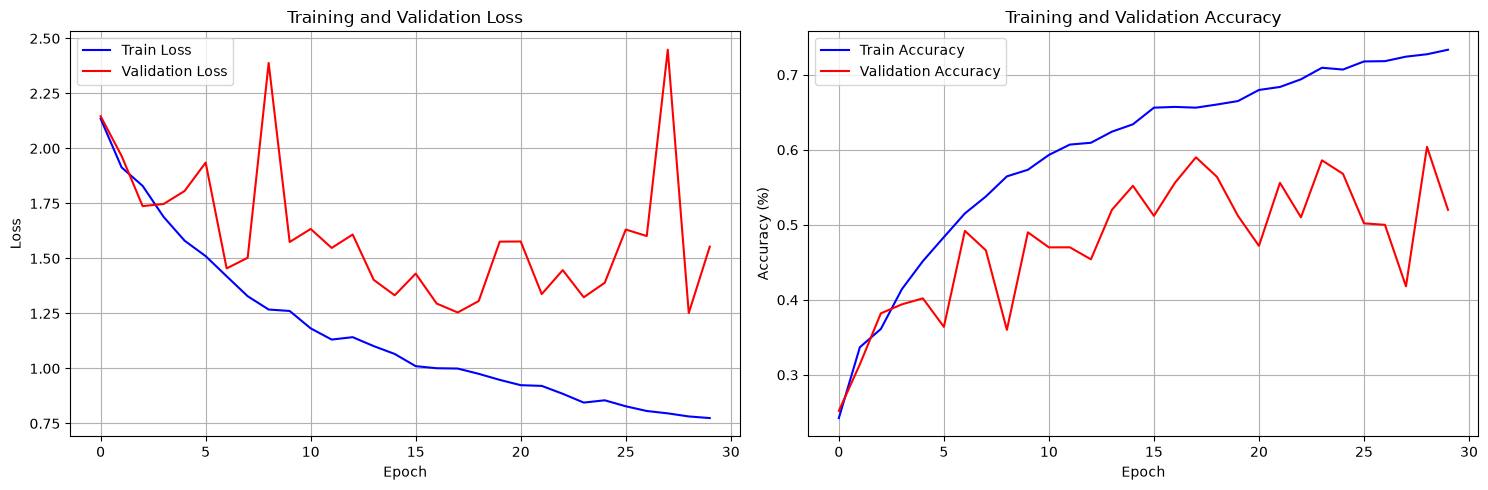

In [36]:
seed_everything(SEED)


model = SimpleResNet18(
    num_classes=10,
    stages=[
        (3, 32),
        (3, 64),
        (3, 128),
        (3, 256)
    ]
)

train_subset_dataset = CustomDataset(subset_train_samples, transform=train_transform)
val_subset_dataset = CustomDataset(subset_val_samples, transform=val_transform)

train_loader = DataLoader(train_subset_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_subset_dataset, batch_size=64, shuffle=False)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f" Всего параметров: {total_params:,}")
print(f" Обучаемых параметров: {trainable_params:,}")
print(model)

history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    criterion=criterion,
    device=device,
    num_epochs=30
)

plot_training_history(history)

best_epoch = int(np.argmax(history["val_acc"]))
experiments_data.append(
    {
        "configuration": "[3,3,3,3] BasicBlock",
        "total_params": total_params,
        "trainable_params": trainable_params,
        "final_val_acc": history["val_acc"][-1],
        "final_train_acc": history["train_acc"][-1],
        "best_val_acc": history["val_acc"][best_epoch],
        "best_train_acc": history["val_acc"][best_epoch],
        "best_epoch": best_epoch
    }
)

#### Лучшая конфигурация (по best_val_acc): [2, 2, 2, 2]
Версия с BottleneckBlock значительно легче, чем аналогичная с BasicBlock. скорости сходимости моделей от 22 до 28 эпох.

In [37]:
pd.DataFrame(experiments_data)

,configuration,total_params,trainable_params,final_val_acc,final_train_acc,best_val_acc,best_train_acc,best_epoch
0,baseline,2779914,2779914,0.620,0.7202,0.620,0.620,29
1,32->64->128->256,1230410,1230410,0.474,0.7524,0.584,0.584,25
2,64->128->256,1228938,1228938,0.544,0.7194,0.562,0.562,17
3,"[1,1,1,1]",1230410,1230410,0.480,0.7558,0.594,0.594,25
4,"[2,2,2,2]",2800010,2800010,0.564,0.7618,0.624,0.624,22
5,"[3,3,3,3] BottleneckBlock",321050,321050,0.514,0.6802,0.600,0.600,26
6,"[3,3,3,3] BasicBlock",4369610,4369610,0.520,0.7334,0.604,0.604,28


#### Эксперименты с функциями активации

#### ReLU

 Всего параметров: 2,800,010
 Обучаемых параметров: 2,800,010
SimpleResNet18(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (activation): ReLU(inplace=True)
  (backbone): Sequential(
    (0): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (activation): ReLU(inplace=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  

Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 44.45it/s]


 Train Loss: 2.0541, Train Acc: 0.27%
 Val Loss: 2.5835, Val Acc: 0.26%
 Сохранена лучшая модель с точностью 0.26%
 Эпоха 2/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 44.45it/s]


 Train Loss: 1.8296, Train Acc: 0.36%
 Val Loss: 1.9588, Val Acc: 0.36%
 Сохранена лучшая модель с точностью 0.36%
 Эпоха 3/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 44.54it/s]


... (51 outputs left out)

Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 44.54it/s]


 Train Loss: 0.7036, Train Acc: 0.75%
 Val Loss: 1.4388, Val Acc: 0.55%
 Эпоха 30/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 44.50it/s]


 Train Loss: 0.7084, Train Acc: 0.76%
 Val Loss: 1.6542, Val Acc: 0.50%


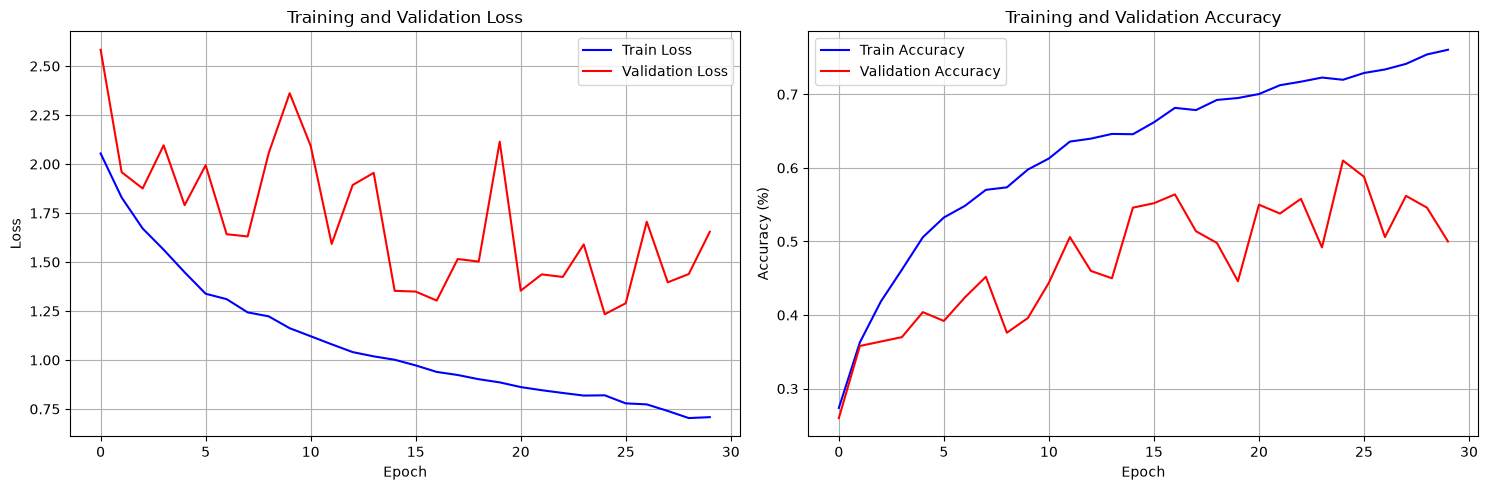

In [38]:
seed_everything(SEED)


model = SimpleResNet18(
    num_classes=10,
    stages=[
        (2, 32),
        (2, 64),
        (2, 128),
        (2, 256)
    ],
    activation = partial(
        nn.ReLU, inplace=True
    )
)

train_subset_dataset = CustomDataset(subset_train_samples, transform=train_transform)
val_subset_dataset = CustomDataset(subset_val_samples, transform=val_transform)

train_loader = DataLoader(train_subset_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_subset_dataset, batch_size=64, shuffle=False)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f" Всего параметров: {total_params:,}")
print(f" Обучаемых параметров: {trainable_params:,}")
print(model)

history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    criterion=criterion,
    device=device,
    num_epochs=30
)

plot_training_history(history)

best_epoch = int(np.argmax(history["val_acc"]))
experiments_data.append(
    {
        "configuration": "ReLU",
        "total_params": total_params,
        "trainable_params": trainable_params,
        "final_val_acc": history["val_acc"][-1],
        "final_train_acc": history["train_acc"][-1],
        "best_val_acc": history["val_acc"][best_epoch],
        "best_train_acc": history["val_acc"][best_epoch],
        "best_epoch": best_epoch
    }
)

#### LeakyReLU

 Всего параметров: 2,800,010
 Обучаемых параметров: 2,800,010
SimpleResNet18(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (activation): LeakyReLU(negative_slope=0.01, inplace=True)
  (backbone): Sequential(
    (0): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (activation): LeakyReLU(negative_slope=0.01, inplace=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, 

Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 46.08it/s]


 Train Loss: 2.0541, Train Acc: 0.27%
 Val Loss: 2.1988, Val Acc: 0.26%
 Сохранена лучшая модель с точностью 0.26%
 Эпоха 2/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 44.24it/s]


 Train Loss: 1.8329, Train Acc: 0.36%
 Val Loss: 1.9500, Val Acc: 0.33%
 Сохранена лучшая модель с точностью 0.33%
 Эпоха 3/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 44.35it/s]


... (51 outputs left out)

Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 44.68it/s]


 Train Loss: 0.7206, Train Acc: 0.75%
 Val Loss: 1.3426, Val Acc: 0.58%
 Эпоха 30/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 44.70it/s]


 Train Loss: 0.7105, Train Acc: 0.76%
 Val Loss: 1.5135, Val Acc: 0.52%


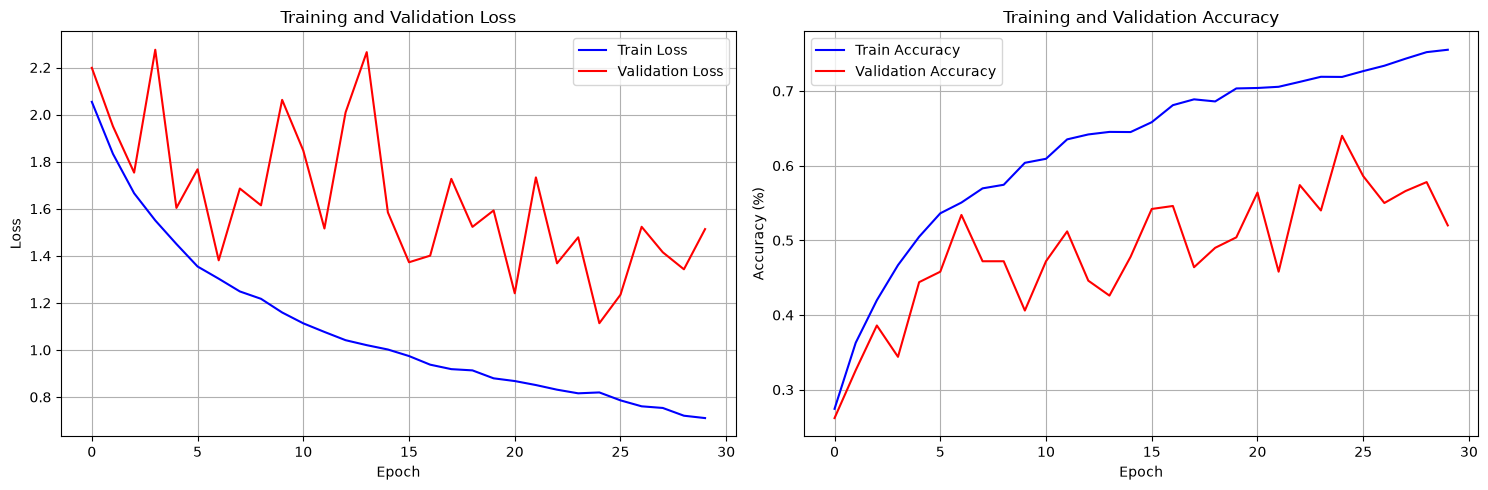

In [39]:
seed_everything(SEED)


model = SimpleResNet18(
    num_classes=10,
    stages=[
        (2, 32),
        (2, 64),
        (2, 128),
        (2, 256)
    ],
    activation = partial(
        nn.LeakyReLU, inplace=True
    )
)

train_subset_dataset = CustomDataset(subset_train_samples, transform=train_transform)
val_subset_dataset = CustomDataset(subset_val_samples, transform=val_transform)

train_loader = DataLoader(train_subset_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_subset_dataset, batch_size=64, shuffle=False)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f" Всего параметров: {total_params:,}")
print(f" Обучаемых параметров: {trainable_params:,}")
print(model)

history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    criterion=criterion,
    device=device,
    num_epochs=30
)

plot_training_history(history)

best_epoch = int(np.argmax(history["val_acc"]))
experiments_data.append(
    {
        "configuration": "LeakyReLU",
        "total_params": total_params,
        "trainable_params": trainable_params,
        "final_val_acc": history["val_acc"][-1],
        "final_train_acc": history["train_acc"][-1],
        "best_val_acc": history["val_acc"][best_epoch],
        "best_train_acc": history["val_acc"][best_epoch],
        "best_epoch": best_epoch
    }
)

#### ELU

 Всего параметров: 2,800,010
 Обучаемых параметров: 2,800,010
SimpleResNet18(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (activation): ELU(alpha=1.0, inplace=True)
  (backbone): Sequential(
    (0): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (activation): ELU(alpha=1.0, inplace=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_ru

Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 44.67it/s]


 Train Loss: 2.0832, Train Acc: 0.27%
 Val Loss: 2.0142, Val Acc: 0.25%
 Сохранена лучшая модель с точностью 0.25%
 Эпоха 2/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 44.65it/s]


 Train Loss: 1.8745, Train Acc: 0.35%
 Val Loss: 2.2282, Val Acc: 0.23%
 Эпоха 3/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 44.87it/s]


... (51 outputs left out)

Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 44.60it/s]


 Train Loss: 0.9086, Train Acc: 0.69%
 Val Loss: 1.2826, Val Acc: 0.56%
 Эпоха 30/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 44.66it/s]


 Train Loss: 0.9222, Train Acc: 0.69%
 Val Loss: 1.3541, Val Acc: 0.53%


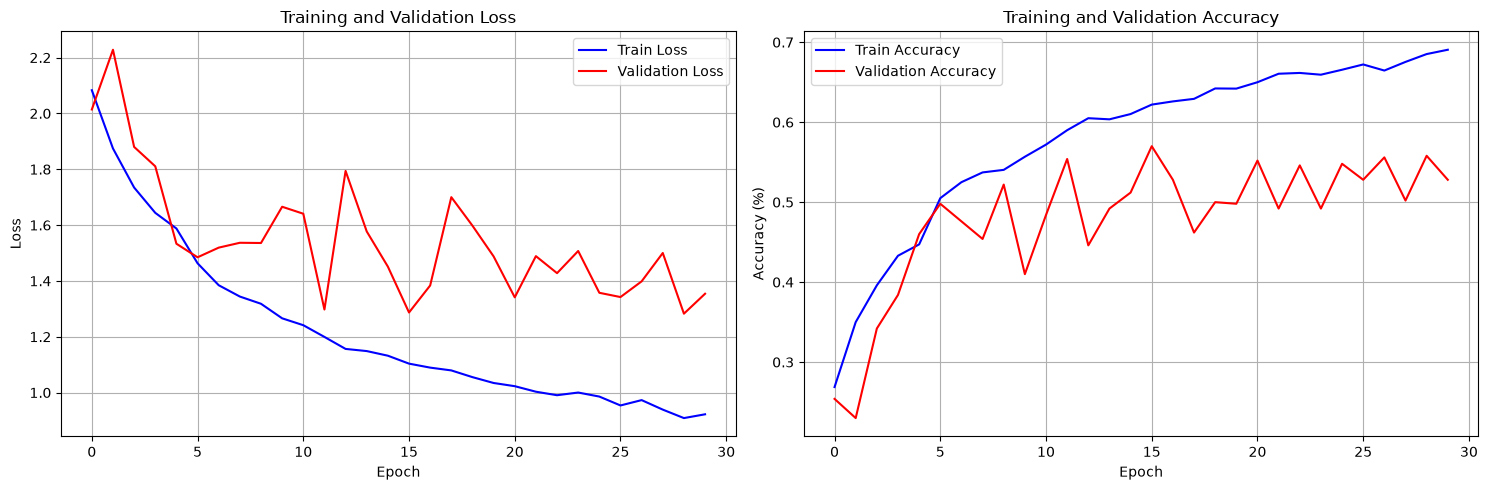

In [40]:
seed_everything(SEED)


model = SimpleResNet18(
    num_classes=10,
    stages=[
        (2, 32),
        (2, 64),
        (2, 128),
        (2, 256)
    ],
    activation = partial(
        nn.ELU, inplace=True
    )
)

train_subset_dataset = CustomDataset(subset_train_samples, transform=train_transform)
val_subset_dataset = CustomDataset(subset_val_samples, transform=val_transform)

train_loader = DataLoader(train_subset_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_subset_dataset, batch_size=64, shuffle=False)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f" Всего параметров: {total_params:,}")
print(f" Обучаемых параметров: {trainable_params:,}")
print(model)

history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    criterion=criterion,
    device=device,
    num_epochs=30
)

plot_training_history(history)

best_epoch = int(np.argmax(history["val_acc"]))
experiments_data.append(
    {
        "configuration": "ELU",
        "total_params": total_params,
        "trainable_params": trainable_params,
        "final_val_acc": history["val_acc"][-1],
        "final_train_acc": history["train_acc"][-1],
        "best_val_acc": history["val_acc"][best_epoch],
        "best_train_acc": history["val_acc"][best_epoch],
        "best_epoch": best_epoch
    }
)

#### GELU

 Всего параметров: 2,800,010
 Обучаемых параметров: 2,800,010
SimpleResNet18(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (activation): GELU(approximate='none')
  (backbone): Sequential(
    (0): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (activation): GELU(approximate='none')
      )
      (1): BasicBlock(
        (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_st

Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 43.46it/s]


 Train Loss: 2.0662, Train Acc: 0.27%
 Val Loss: 2.4810, Val Acc: 0.23%
 Сохранена лучшая модель с точностью 0.23%
 Эпоха 2/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 43.67it/s]


 Train Loss: 1.8420, Train Acc: 0.35%
 Val Loss: 1.9883, Val Acc: 0.31%
 Сохранена лучшая модель с точностью 0.31%
 Эпоха 3/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 43.62it/s]


... (51 outputs left out)

Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 42.30it/s]


 Train Loss: 0.6809, Train Acc: 0.76%
 Val Loss: 1.3418, Val Acc: 0.55%
 Эпоха 30/30


Validation: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 43.67it/s]


 Train Loss: 0.6555, Train Acc: 0.77%
 Val Loss: 1.4248, Val Acc: 0.55%


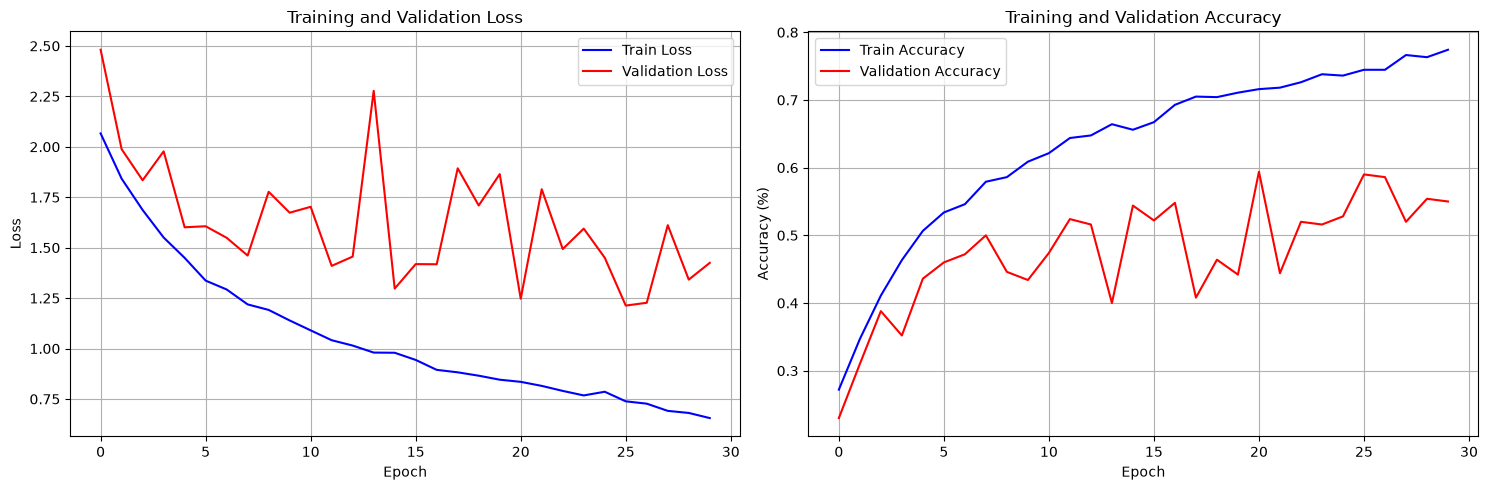

In [41]:
seed_everything(SEED)


model = SimpleResNet18(
    num_classes=10,
    stages=[
        (2, 32),
        (2, 64),
        (2, 128),
        (2, 256)
    ],
    activation = nn.GELU
)

train_subset_dataset = CustomDataset(subset_train_samples, transform=train_transform)
val_subset_dataset = CustomDataset(subset_val_samples, transform=val_transform)

train_loader = DataLoader(train_subset_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_subset_dataset, batch_size=64, shuffle=False)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f" Всего параметров: {total_params:,}")
print(f" Обучаемых параметров: {trainable_params:,}")
print(model)

history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    criterion=criterion,
    device=device,
    num_epochs=30
)

plot_training_history(history)

best_epoch = int(np.argmax(history["val_acc"]))
experiments_data.append(
    {
        "configuration": "GELU",
        "total_params": total_params,
        "trainable_params": trainable_params,
        "final_val_acc": history["val_acc"][-1],
        "final_train_acc": history["train_acc"][-1],
        "best_val_acc": history["val_acc"][best_epoch],
        "best_train_acc": history["val_acc"][best_epoch],
        "best_epoch": best_epoch
    }
)

#### Лучшая конфигурация (по best_val_acc): LeakyReLU
скорости сходимости от 15 до 24 эпох

In [42]:
pd.DataFrame(experiments_data)

,configuration,total_params,trainable_params,final_val_acc,final_train_acc,best_val_acc,best_train_acc,best_epoch
0,baseline,2779914,2779914,0.620,0.7202,0.620,0.620,29
1,32->64->128->256,1230410,1230410,0.474,0.7524,0.584,0.584,25
2,64->128->256,1228938,1228938,0.544,0.7194,0.562,0.562,17
3,"[1,1,1,1]",1230410,1230410,0.480,0.7558,0.594,0.594,25
4,"[2,2,2,2]",2800010,2800010,0.564,0.7618,0.624,0.624,22
5,"[3,3,3,3] BottleneckBlock",321050,321050,0.514,0.6802,0.600,0.600,26
6,"[3,3,3,3] BasicBlock",4369610,4369610,0.520,0.7334,0.604,0.604,28
7,ReLU,2800010,2800010,0.500,0.7606,0.610,0.610,24
8,LeakyReLU,2800010,2800010,0.520,0.7552,0.640,0.640,24
9,ELU,2800010,2800010,0.528,0.6906,0.570,0.570,15
